# Етап 5 — Аналіз помилок («де саме моделі сліпі»)

Мета (за планом): побудувати матриці плутанини для поведінкової та
мережевої моделей окремо, з'ясувати, на яких **типах** ботів/атак кожна
модель найчастіше помиляється, і сформулювати аргумент на користь
гібридної (fusion) моделі.

**Важливе методологічне уточнення.** Поведінкові дані (DELBOT-Mouse,
CaptchaSolve30k) і мережеві дані (CIC-IDS2017, UNSW-NB15, CTU-13) — це
два повністю незалежні датасети: жоден приклад не має одночасно і
траєкторії миші, і мережевого потоку. Тому буквальний "перетин помилок
по конкретних прикладах" (чи модель А помиляється саме там, де помиляється
модель Б) тут неможливий. Замість цього робимо чесніший, якісний аналіз:
незалежно з'ясовуємо, на яких ТИПАХ прикладів "сліпа" кожна модель, і
аргументуємо потребу в fusion тим, що ці слабкі місця мають різну природу.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q xgboost

import os
import glob
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, recall_score

PROJECT_DIR = '/content/drive/MyDrive/man-bot-detection'
OUTPUT_DIR = os.path.join(PROJECT_DIR, 'notebooks/results')
os.makedirs(os.path.join(OUTPUT_DIR, 'figures'), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'tables'), exist_ok=True)

Mounted at /content/drive


## Частина A. Поведінкова модель — помилки по ПІДТИПАХ бота/людини

Збережений `behavioral_features_windowed.csv` (з 02) знає лише "грубе"
джерело (`delbot_mouse_bot`/`delbot_mouse_human`/`captchasolve30k_human`).
Для аналізу помилок за планом (п.48) потрібен ДРІБНІШИЙ поділ — конкретний
підтип бота (`circles_bot_gan`, `circles_bot_pynput`, `circles_bot_pyhm`,
`circles_bot_naturalmousemotion`). Тому тут заново рахуємо ознаки вікна,
але зберігаємо ім'я підпапки як точне джерело.

In [2]:
DELBOT_PATH = f'{PROJECT_DIR}/data/raw/delbot_mouse'
WINDOW_SIZE = 100
STEP = 50


def normalize_coords(traj):
    if len(traj) == 0:
        return traj
    min_x, max_x = np.min(traj[:, 0]), np.max(traj[:, 0])
    min_y, max_y = np.min(traj[:, 1]), np.max(traj[:, 1])
    range_x = max_x - min_x if max_x - min_x > 0 else 1
    range_y = max_y - min_y if max_y - min_y > 0 else 1
    norm_x = (traj[:, 0] - min_x) / range_x * 200
    norm_y = (traj[:, 1] - min_y) / range_y * 200
    return np.column_stack((norm_x, norm_y))


def load_delbot_trajectory(file_path):
    """Той самий парсер реального формату DELBOT-Mouse, що й у 02
    (time,Action,x,y, з фільтром NaN/Inf)."""
    coords, is_down_flags = [], []
    is_down = 0
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('resolution'):
                continue
            parts = line.split(',')
            if len(parts) < 4:
                continue
            action = parts[1]
            try:
                x = float(parts[2])
                y = float(parts[3])
            except ValueError:
                continue
            if not (np.isfinite(x) and np.isfinite(y)):
                continue
            if action == 'Pressed':
                is_down = 1
            elif action == 'Released':
                is_down = 0
            coords.append((x, y))
            is_down_flags.append(is_down)
    return (np.array(coords, dtype=np.float32),
            np.array(is_down_flags, dtype=np.int32))


def extract_window_features(window_coords, window_clicks=None):
    if len(window_coords) < 5:
        return None
    dx = np.diff(window_coords[:, 0])
    dy = np.diff(window_coords[:, 1])
    speeds = np.sqrt(dx**2 + dy**2)
    if len(speeds) == 0:
        return None
    mean_speed, max_speed, std_speed = np.mean(speeds), np.max(speeds), np.std(speeds)
    path_length = np.sum(speeds)
    num_stops = np.sum(speeds < 0.5)
    angles = np.arctan2(dy, dx)
    if len(angles) > 1:
        angle_diffs = np.abs(np.diff(angles))
        angle_diffs = np.minimum(angle_diffs, 2*np.pi - angle_diffs)
        mean_angle = np.mean(angle_diffs)
    else:
        mean_angle = 0
    num_clicks = 0
    if window_clicks is not None and len(window_clicks) == len(window_coords):
        num_clicks = np.sum((window_clicks[1:] == 1) & (window_clicks[:-1] == 0))
    return {
        'mean_speed': mean_speed, 'max_speed': max_speed, 'std_speed': std_speed,
        'path_length': path_length, 'num_stops': num_stops, 'mean_angle': mean_angle,
        'num_clicks': num_clicks, 'num_points': len(window_coords)
    }


def process_files_finegrained(file_list, label, subtype):
    rows = []
    for file_path in file_list:
        try:
            coords, is_down = load_delbot_trajectory(file_path)
            if len(coords) < WINDOW_SIZE:
                continue
            coords_norm = normalize_coords(coords)
            for start in range(0, len(coords_norm) - WINDOW_SIZE + 1, STEP):
                wc = coords_norm[start:start+WINDOW_SIZE]
                wcl = is_down[start:start+WINDOW_SIZE]
                feats = extract_window_features(wc, wcl)
                if feats is None:
                    continue
                feats['label'] = label
                feats['subtype'] = subtype
                rows.append(feats)
        except Exception:
            continue
    return rows

In [3]:
all_rows = []
for folder in sorted(glob.glob(f'{DELBOT_PATH}/circles_human_*')):
    subtype = os.path.basename(folder)
    files = glob.glob(f'{folder}/*')
    all_rows += process_files_finegrained(files, 'human', subtype)
    print(f"  {subtype}: {len(files)} файлів оброблено")

for folder in sorted(glob.glob(f'{DELBOT_PATH}/circles_bot_*')):
    subtype = os.path.basename(folder)
    files = glob.glob(f'{folder}/*')
    all_rows += process_files_finegrained(files, 'bot', subtype)
    print(f"  {subtype}: {len(files)} файлів оброблено")

df_behav_fine = pd.DataFrame(all_rows)
print(f"\n✅ Всього вікон (з підтипами, лише DELBOT-Mouse): {len(df_behav_fine)}")
print(df_behav_fine['subtype'].value_counts())

  circles_human_fast: 9 файлів оброблено
  circles_human_pc1: 187 файлів оброблено
  circles_human_pc2: 459 файлів оброблено
  circles_human_pc2_pad: 62 файлів оброблено
  circles_human_tel: 98 файлів оброблено
  circles_human_vm: 140 файлів оброблено
  circles_bot_gan: 1899 файлів оброблено
  circles_bot_naturalmousemotion: 234 файлів оброблено
  circles_bot_pyhm: 55 файлів оброблено
  circles_bot_pynput: 408 файлів оброблено

✅ Всього вікон (з підтипами, лише DELBOT-Mouse): 4313
subtype
circles_bot_naturalmousemotion    2833
circles_human_pc2                  741
circles_bot_pynput                 315
circles_human_fast                 148
circles_human_pc1                  130
circles_human_tel                   53
circles_human_vm                    40
circles_human_pc2_pad               36
circles_bot_pyhm                    17
Name: count, dtype: int64


### Завантажуємо вже навчену модель (behavioral_rf_300.pkl) і рахуємо помилки

=== Загальна матриця плутанини (поведінкова модель, DELBOT-Mouse, усі підтипи разом) ===
            pred_human  pred_bot
true_human        1141         7
true_bot           109      3056

              precision    recall  f1-score   support

         bot       1.00      0.97      0.98      3165
       human       0.91      0.99      0.95      1148

    accuracy                           0.97      4313
   macro avg       0.96      0.98      0.97      4313
weighted avg       0.98      0.97      0.97      4313


=== Точність розпізнавання ПО КОЖНОМУ ПІДТИПУ (від найгіршого до найкращого) ===
                                n_windows  accuracy true_label
subtype                                                       
circles_bot_pyhm                       17  0.941176        bot
circles_bot_pynput                    315  0.958730        bot
circles_bot_naturalmousemotion       2833  0.966467        bot
circles_human_pc2                     741  0.990553      human
circles_human_fast      

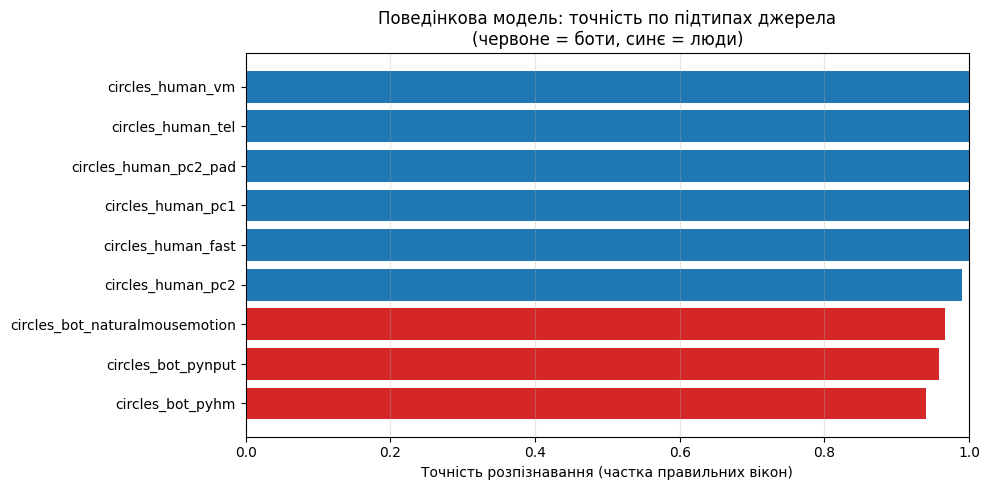


📌 Найгірше розпізнаваний підтип бота: circles_bot_pyhm


In [4]:
FEATURE_COLS = ['mean_speed', 'max_speed', 'std_speed', 'path_length',
                 'num_stops', 'mean_angle', 'num_clicks', 'num_points']

rf_behav = joblib.load(f'{PROJECT_DIR}/models/behavioral_rf_300.pkl')

X_fine = df_behav_fine[FEATURE_COLS]
y_fine_true = df_behav_fine['label']
y_fine_pred = rf_behav.predict(X_fine)

print("=== Загальна матриця плутанини (поведінкова модель, DELBOT-Mouse, усі підтипи разом) ===")
cm = confusion_matrix(y_fine_true, y_fine_pred, labels=['human', 'bot'])
print(pd.DataFrame(cm, index=['true_human', 'true_bot'], columns=['pred_human', 'pred_bot']))
print()
print(classification_report(y_fine_true, y_fine_pred, zero_division=0))

                                                                              
df_behav_fine['pred'] = y_fine_pred
df_behav_fine['correct'] = (df_behav_fine['label'] == df_behav_fine['pred'])

subtype_report = (
    df_behav_fine.groupby('subtype')
    .agg(n_windows=('correct', 'size'),
         accuracy=('correct', 'mean'),
         true_label=('label', 'first'))
    .sort_values('accuracy')
)
print("\n=== Точність розпізнавання ПО КОЖНОМУ ПІДТИПУ (від найгіршого до найкращого) ===")
print(subtype_report.to_string())
subtype_report.to_csv(os.path.join(OUTPUT_DIR, 'tables', 'behavioral_subtype_errors.csv'))

        
plt.figure(figsize=(10, 5))
colors = ['tab:red' if lbl == 'bot' else 'tab:blue' for lbl in subtype_report['true_label']]
plt.barh(subtype_report.index, subtype_report['accuracy'], color=colors)
plt.xlabel('Точність розпізнавання (частка правильних вікон)')
plt.title('Поведінкова модель: точність по підтипах джерела\n(червоне = боти, синє = люди)')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'figures', 'behavioral_subtype_accuracy.png'), dpi=300)
plt.show()

print("\n📌 Найгірше розпізнаваний підтип бота:",
      subtype_report[subtype_report['true_label'] == 'bot'].index[0]
      if (subtype_report['true_label'] == 'bot').any() else "—")

## Частина B. Мережева модель — помилки по ТИПАХ атак (CIC, UNSW)

`label` у 03 — бінарна (0=норма, 1=атака). Тут повторно завантажуємо
CIC/UNSW і зберігаємо ще й МУЛЬТИКЛАСОВУ мітку (тип атаки), щоб після
навчання подивитись recall окремо для кожного типу — саме це прохання
п.49 плану ("які атаки найчастіше не розпізнаються").

In [5]:
DATA_BASE = os.path.join(PROJECT_DIR, 'data/raw')
PATHS = {
    'CIC': os.path.join(DATA_BASE, 'cic_ids_2017'),
    'UNSW': os.path.join(DATA_BASE, 'unsw_nb15'),
}


def load_cic_with_multiclass():
    files = glob.glob(os.path.join(PATHS['CIC'], '*.csv'))
    df = pd.concat([pd.read_csv(f, low_memory=False) for f in files], ignore_index=True)
    if len(df) > 200000:
        df = df.sample(n=200000, random_state=42)
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    y_multi = df[' Label'].astype(str).str.strip()
    y_binary = (y_multi != 'BENIGN').astype(int)
    X = df.drop(columns=[' Label']).select_dtypes(include=[np.number])
    return X.reset_index(drop=True), y_binary.reset_index(drop=True), y_multi.reset_index(drop=True)


def load_unsw_with_multiclass():
    df_train = pd.read_csv(os.path.join(PATHS['UNSW'], 'UNSW_NB15_training-set.csv'), low_memory=False)
    df_test = pd.read_csv(os.path.join(PATHS['UNSW'], 'UNSW_NB15_testing-set.csv'), low_memory=False)
    df = pd.concat([df_train, df_test], ignore_index=True)
    if len(df) > 200000:
        df = df.sample(n=200000, random_state=42)
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    y_multi = df['attack_cat'].astype(str).str.strip()
    y_binary = (y_multi.str.lower() != 'normal').astype(int)
    X = df.drop(columns=['attack_cat', 'label']).select_dtypes(include=[np.number])
    return X.reset_index(drop=True), y_binary.reset_index(drop=True), y_multi.reset_index(drop=True)


def analyze_network_errors(name, X, y_binary, y_multi):
    print(f"\n{'='*60}\n🔄 {name}\n{'='*60}")
    X_train, X_test, y_train, y_test, ymulti_train, ymulti_test = train_test_split(
        X, y_binary, y_multi, test_size=0.2, random_state=42, stratify=y_binary
    )
    model = RandomForestClassifier(n_estimators=50, random_state=42,
                                    class_weight='balanced', n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"Загальна матриця плутанини ({name}):")
    cm = confusion_matrix(y_test, y_pred)
    print(pd.DataFrame(cm, index=['true_0', 'true_1'], columns=['pred_0', 'pred_1']))

                                                                                 
    results = []
    for attack_type in sorted(ymulti_test.unique()):
        mask = (ymulti_test == attack_type)
        if mask.sum() == 0:
            continue
        true_label = y_test[mask].iloc[0]                                      
        recall_type = (y_pred[mask.values] == true_label).mean()
        results.append({'attack_type': attack_type, 'n_samples': int(mask.sum()),
                         'is_attack': bool(true_label == 1), 'recall': recall_type})

    df_type_report = pd.DataFrame(results).sort_values('recall')
    print(f"\n=== Recall по кожному типу трафіку ({name}), від найгіршого ===")
    print(df_type_report.to_string(index=False))
    df_type_report.to_csv(os.path.join(OUTPUT_DIR, 'tables', f'network_{name}_type_errors.csv'), index=False)

    plt.figure(figsize=(10, 5))
    colors = ['tab:red' if a else 'tab:blue' for a in df_type_report['is_attack']]
    plt.barh(df_type_report['attack_type'], df_type_report['recall'], color=colors)
    plt.xlabel('Recall (частка правильно класифікованих)')
    plt.title(f'Мережева модель ({name}): recall по типах трафіку\n(червоне = атаки, синє = норма)')
    plt.xlim(0, 1)
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'figures', f'network_{name}_type_recall.png'), dpi=300)
    plt.show()

    worst = df_type_report[df_type_report['is_attack']].iloc[0] if df_type_report['is_attack'].any() else None
    if worst is not None:
        print(f"\n📌 Найгірше розпізнавана атака в {name}: '{worst['attack_type']}' "
              f"(recall={worst['recall']:.4f}, n={worst['n_samples']})")
    return df_type_report


🔄 CIC
Загальна матриця плутанини (CIC):
        pred_0  pred_1
true_0   26188      17
true_1      28   13717

=== Recall по кожному типу трафіку (CIC), від найгіршого ===
     attack_type  n_samples  is_attack   recall
             Bot         60       True 0.816667
   DoS slowloris        220       True 0.981818
        DoS Hulk       8215       True 0.998904
            DDoS       4693       True 0.999148
          BENIGN      26205      False 0.999351
   DoS GoldenEye        373       True 1.000000
DoS Slowhttptest        184       True 1.000000


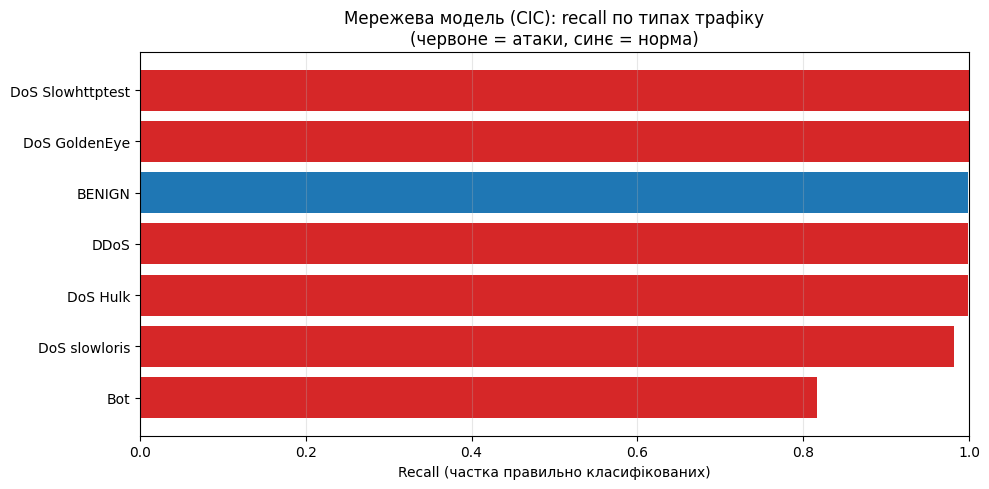


📌 Найгірше розпізнавана атака в CIC: 'Bot' (recall=0.8167, n=60)


In [6]:
X_cic, y_cic_bin, y_cic_multi = load_cic_with_multiclass()
cic_type_report = analyze_network_errors('CIC', X_cic, y_cic_bin, y_cic_multi)


🔄 UNSW
Загальна матриця плутанини (UNSW):
        pred_0  pred_1
true_0   14061     360
true_1     353   25226

=== Recall по кожному типу трафіку (UNSW), від найгіршого ===
   attack_type  n_samples  is_attack   recall
       Fuzzers       3796       True 0.923604
        Normal      14421      False 0.975036
      Analysis        421       True 0.978622
     Shellcode        259       True 0.992278
      Exploits       7014       True 0.994725
Reconnaissance       2186       True 0.996340
           DoS       2528       True 0.998022
       Generic       8961       True 0.999777
      Backdoor        392       True 1.000000
         Worms         22       True 1.000000


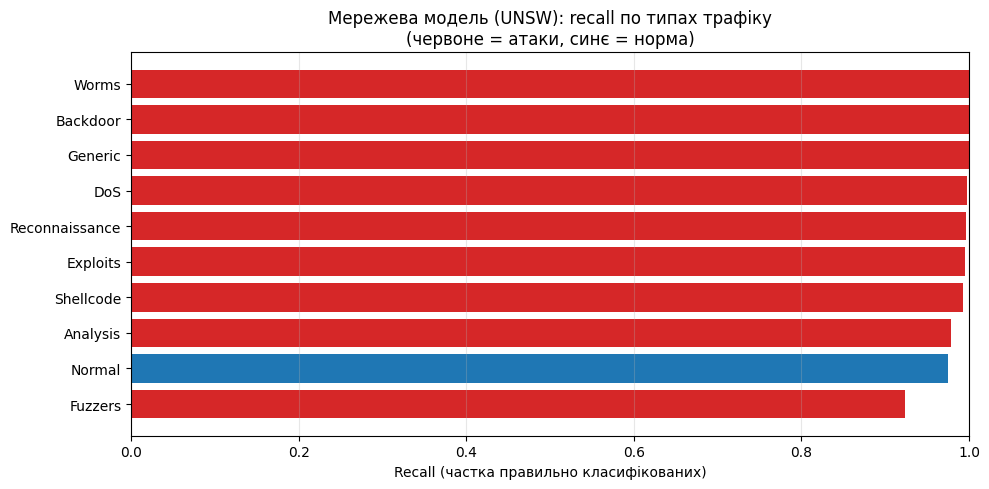


📌 Найгірше розпізнавана атака в UNSW: 'Fuzzers' (recall=0.9236, n=3796)


In [7]:
X_unsw, y_unsw_bin, y_unsw_multi = load_unsw_with_multiclass()
unsw_type_report = analyze_network_errors('UNSW', X_unsw, y_unsw_bin, y_unsw_multi)

ℹ️ CTU-13 тут навмисно пропущено: у ньому лише бінарна мітка
(Botnet/Normal), без розбивки на типи атак/ботнетів — типового аналізу
"по типу атаки" для нього побудувати неможливо через відсутність даних,
а не через помилку коду.

## Частина A2. Чи можна взагалі відрізнити GAN-боти від людини? (коротке вікно)

`circles_bot_gan` — найбільша підгрупа ботів (1899 з 2596 файлів, 73%) і,
судячи з назви, найважливіша для теми роботи (GAN спеціально тренований
генерувати траєкторії, схожі на людські). У Частині A вона повністю
випала з аналізу, бо GAN-файли переважно короткі (~27-52 точки) —
коротші за WINDOW_SIZE=100. Тут повторюємо весь пайплайн з набагато
меншим вікном (20 точок), щоб охопити й ці файли, і робимо це для ВСІХ
підтипів одразу (не тільки GAN) — щоб порівняння між підтипами лишалось
чесним (усі оцінюються на тому самому розмірі вікна).

⚠️ Це ОКРЕМИЙ експеримент з окремою моделлю — не той самий
`behavioral_rf_300.pkl`, який навчений на 100-точкових вікнах. Абсолютні
цифри тут не можна напряму порівнювати з Частиною A (різний розмір вікна
= різна статистична потужність ознак типу num_stops/path_length), але
порівняння ПІДТИПІВ МІЖ СОБОЮ в межах цього експерименту — коректне.

In [8]:
WINDOW_SIZE_SMALL = 20
STEP_SMALL = 10


def process_files_finegrained_small(file_list, label, subtype):
    rows = []
    for file_path in file_list:
        try:
            coords, is_down = load_delbot_trajectory(file_path)
            if len(coords) < WINDOW_SIZE_SMALL:
                continue
            coords_norm = normalize_coords(coords)
            for start in range(0, len(coords_norm) - WINDOW_SIZE_SMALL + 1, STEP_SMALL):
                wc = coords_norm[start:start+WINDOW_SIZE_SMALL]
                wcl = is_down[start:start+WINDOW_SIZE_SMALL]
                feats = extract_window_features(wc, wcl)
                if feats is None:
                    continue
                feats['label'] = label
                feats['subtype'] = subtype
                rows.append(feats)
        except Exception:
            continue
    return rows


all_rows_small = []
for folder in sorted(glob.glob(f'{DELBOT_PATH}/circles_human_*')):
    subtype = os.path.basename(folder)
    files = glob.glob(f'{folder}/*')
    all_rows_small += process_files_finegrained_small(files, 'human', subtype)

for folder in sorted(glob.glob(f'{DELBOT_PATH}/circles_bot_*')):
    subtype = os.path.basename(folder)
    files = glob.glob(f'{folder}/*')
    all_rows_small += process_files_finegrained_small(files, 'bot', subtype)

df_behav_small = pd.DataFrame(all_rows_small)
print(f"✅ Всього вікон (WINDOW_SIZE={WINDOW_SIZE_SMALL}, усі підтипи включно з GAN): {len(df_behav_small)}")
print(df_behav_small['subtype'].value_counts())

✅ Всього вікон (WINDOW_SIZE=20, усі підтипи включно з GAN): 33924
subtype
circles_bot_naturalmousemotion    15548
circles_human_pc2                  6261
circles_bot_gan                    3954
circles_bot_pynput                 3283
circles_human_pc1                  1710
circles_human_fast                  798
circles_human_vm                    747
circles_human_tel                   706
circles_human_pc2_pad               529
circles_bot_pyhm                    388
Name: count, dtype: int64


=== Загальна матриця плутанини (коротке вікно, усі підтипи включно з GAN) ===
            pred_human  pred_bot
true_human        1627       523
true_bot           516      4119

              precision    recall  f1-score   support

         bot       0.89      0.89      0.89      4635
       human       0.76      0.76      0.76      2150

    accuracy                           0.85      6785
   macro avg       0.82      0.82      0.82      6785
weighted avg       0.85      0.85      0.85      6785


=== Точність по підтипах (коротке вікно, GAN включено) ===
                                n_windows  accuracy true_label
subtype                                                       
circles_human_pc2_pad                 124  0.685484      human
circles_human_pc2                    1257  0.721559      human
circles_bot_pynput                    706  0.779037        bot
circles_human_tel                     143  0.783217      human
circles_human_pc1                     333  0.822823      

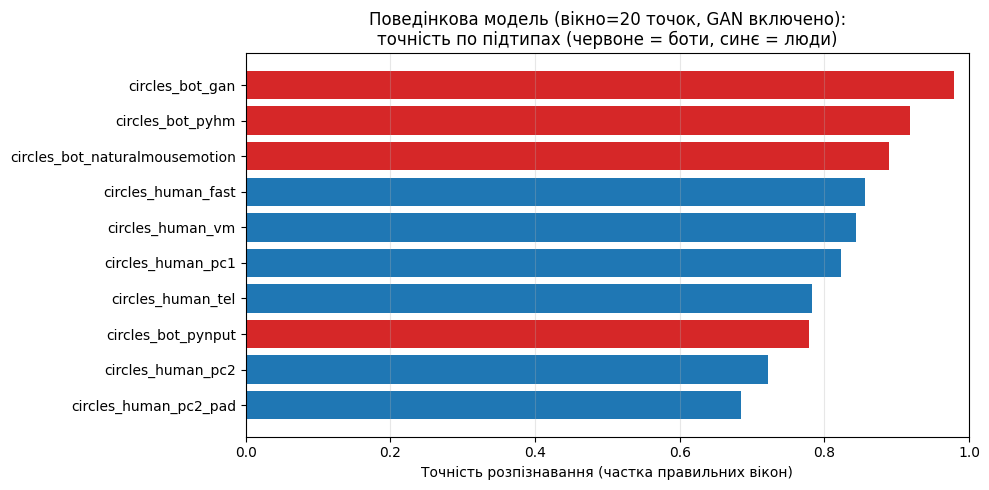


📌 circles_bot_gan (найбільша підгрупа ботів, 787 тестових вікон): точність розпізнавання = 0.9797


In [9]:
X_small = df_behav_small[FEATURE_COLS]
y_small = df_behav_small['label']

X_tr_s, X_te_s, y_tr_s, y_te_s, idx_tr_s, idx_te_s = train_test_split(
    X_small, y_small, df_behav_small.index, test_size=0.2, random_state=42, stratify=y_small
)

rf_small = RandomForestClassifier(n_estimators=200, random_state=42,
                                   class_weight='balanced', n_jobs=-1)
rf_small.fit(X_tr_s, y_tr_s)
y_pred_s = rf_small.predict(X_te_s)

print("=== Загальна матриця плутанини (коротке вікно, усі підтипи включно з GAN) ===")
cm_s = confusion_matrix(y_te_s, y_pred_s, labels=['human', 'bot'])
print(pd.DataFrame(cm_s, index=['true_human', 'true_bot'], columns=['pred_human', 'pred_bot']))
print()
print(classification_report(y_te_s, y_pred_s, zero_division=0))

test_subtypes = df_behav_small.loc[idx_te_s, 'subtype'].values
df_test_small = pd.DataFrame({
    'subtype': test_subtypes, 'label': y_te_s.values, 'pred': y_pred_s
})
df_test_small['correct'] = (df_test_small['label'] == df_test_small['pred'])

subtype_report_small = (
    df_test_small.groupby('subtype')
    .agg(n_windows=('correct', 'size'), accuracy=('correct', 'mean'),
         true_label=('label', 'first'))
    .sort_values('accuracy')
)
print("\n=== Точність по підтипах (коротке вікно, GAN включено) ===")
print(subtype_report_small.to_string())
subtype_report_small.to_csv(os.path.join(OUTPUT_DIR, 'tables', 'behavioral_subtype_errors_smallwindow.csv'))

plt.figure(figsize=(10, 5))
colors_s = ['tab:red' if lbl == 'bot' else 'tab:blue' for lbl in subtype_report_small['true_label']]
plt.barh(subtype_report_small.index, subtype_report_small['accuracy'], color=colors_s)
plt.xlabel('Точність розпізнавання (частка правильних вікон)')
plt.title(f'Поведінкова модель (вікно={WINDOW_SIZE_SMALL} точок, GAN включено):\n'
          'точність по підтипах (червоне = боти, синє = люди)')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'figures', 'behavioral_subtype_accuracy_smallwindow.png'), dpi=300)
plt.show()

if 'circles_bot_gan' in subtype_report_small.index:
    gan_acc = subtype_report_small.loc['circles_bot_gan', 'accuracy']
    gan_n = subtype_report_small.loc['circles_bot_gan', 'n_windows']
    print(f"\n📌 circles_bot_gan (найбільша підгрупа ботів, {gan_n} тестових вікон): "
          f"точність розпізнавання = {gan_acc:.4f}")
    if gan_acc < 0.8:
        print("   ⚠️ Це суттєво нижче за інші підтипи — GAN-генеровані траєкторії "
              "справді найкраще маскуються під людину.")
else:
    print("\n⚠️ circles_bot_gan все одно відсутній навіть при WINDOW_SIZE=20 — "
          "варто перевірити мінімальну довжину файлів цієї підгрупи окремо.")

worst_bot_overall = subtype_report_small[subtype_report_small['true_label'] == 'bot'].index[0] \
    if (subtype_report_small['true_label'] == 'bot').any() else "н/д"
worst_bot_overall_acc = subtype_report_small[subtype_report_small['true_label'] == 'bot']['accuracy'].iloc[0] \
    if (subtype_report_small['true_label'] == 'bot').any() else float('nan')

## Частина C. Підсумковий якісний висновок (п.50–51 плану)

In [10]:
worst_behav_bot = subtype_report[subtype_report['true_label'] == 'bot'].index[0] \
    if (subtype_report['true_label'] == 'bot').any() else "н/д"
worst_behav_acc = subtype_report[subtype_report['true_label'] == 'bot']['accuracy'].iloc[0] \
    if (subtype_report['true_label'] == 'bot').any() else float('nan')

worst_cic = cic_type_report[cic_type_report['is_attack']].iloc[0] if cic_type_report['is_attack'].any() else None
worst_unsw = unsw_type_report[unsw_type_report['is_attack']].iloc[0] if unsw_type_report['is_attack'].any() else None

worst_cic_name = worst_cic['attack_type'] if worst_cic is not None else 'н/д'
worst_cic_recall = worst_cic['recall'] if worst_cic is not None else 0.0
worst_unsw_name = worst_unsw['attack_type'] if worst_unsw is not None else 'н/д'
worst_unsw_recall = worst_unsw['recall'] if worst_unsw is not None else 0.0

print("="*70)
print("ПІДСУМОК: де саме моделі \"сліпі\"")
print("="*70)
print(f"""
1a. НА ПОВНОМУ ВІКНІ (100 точок, GAN виключено через коротку довжину)
    найгірше розпізнається підтип '{worst_behav_bot}' (точність {worst_behav_acc:.4f}).

1b. НА КОРОТКОМУ ВІКНІ (20 точок, GAN включено — Частина A2) найгірше
    розпізнається підтип '{worst_bot_overall}' (точність {worst_bot_overall_acc:.4f}).
    Це і є найповніша, чесна відповідь на п.48 плану: враховує ВСІ підтипи
    бота, включно з найбільшою (GAN) підгрупою, яку неможливо було оцінити
    при більшому вікні.

2. МЕРЕЖЕВА МОДЕЛЬ найгірше ловить:
   - у CIC-IDS2017: '{worst_cic_name}' (recall={worst_cic_recall:.4f})
   - у UNSW-NB15: '{worst_unsw_name}' (recall={worst_unsw_recall:.4f})

3. ЯКІСНИЙ АРГУМЕНТ ДЛЯ FUSION (з урахуванням обмеження незалежних
   датасетів — див. примітку на початку ноутбука):
   Слабкі місця двох моделей мають РІЗНУ природу — поведінкова модель
   плутається на конкретному способі ІМІТАЦІЇ РУХУ (наприклад, GAN- чи
   бібліотечно згенерована траєкторія), тоді як мережева модель плутається
   на конкретному ПРОТОКОЛЬНОМУ ПpaTTERNI трафіку (тип атаки, що маскується
   під нормальний трафік за обсягом/частотою пакетів). Оскільки джерело
   помилки в кожному випадку принципово різне (геометрія руху миші проти
   характеристик мережевого потоку), об'єднання цих двох незалежних сигналів
   у гібридній моделі (крок 6) має сенс: приклад, що обманює одну модель,
   навряд чи одночасно обманює й іншу, оскільки ознаки, на яких вони
   базуються, не перетинаються.
""")

ПІДСУМОК: де саме моделі "сліпі"

1a. НА ПОВНОМУ ВІКНІ (100 точок, GAN виключено через коротку довжину)
    найгірше розпізнається підтип 'circles_bot_pyhm' (точність 0.9412).

1b. НА КОРОТКОМУ ВІКНІ (20 точок, GAN включено — Частина A2) найгірше
    розпізнається підтип 'circles_bot_pynput' (точність 0.7790).
    Це і є найповніша, чесна відповідь на п.48 плану: враховує ВСІ підтипи
    бота, включно з найбільшою (GAN) підгрупою, яку неможливо було оцінити
    при більшому вікні.

2. МЕРЕЖЕВА МОДЕЛЬ найгірше ловить:
   - у CIC-IDS2017: 'Bot' (recall=0.8167)
   - у UNSW-NB15: 'Fuzzers' (recall=0.9236)

3. ЯКІСНИЙ АРГУМЕНТ ДЛЯ FUSION (з урахуванням обмеження незалежних
   датасетів — див. примітку на початку ноутбука):
   Слабкі місця двох моделей мають РІЗНУ природу — поведінкова модель
   плутається на конкретному способі ІМІТАЦІЇ РУХУ (наприклад, GAN- чи
   бібліотечно згенерована траєкторія), тоді як мережева модель плутається
   на конкретному ПРОТОКОЛЬНОМУ ПpaTTERNI трафіку (тип а